# Lab 04 – Comparing Supervised Learning Algorithms Using Model Evaluation Techniques

## Part I – Load the Prepared Dataset

This notebook compares Logistic Regression, Decision Tree, and Gaussian Naïve Bayes
for predicting school attendance among individuals aged 5–24 using the APIS 2022 dataset.

In [ ]:
# IMPORT ALL REQUIRED LIBRARIES

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and cross-validation
from sklearn.model_selection import StratifiedGroupKFold

# Pipeline and preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# Model utilities
from sklearn.base import clone

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    average_precision_score
)

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [ ]:
# LOAD THE PREPARED DATASET

df = pd.read_csv("/content/APIS_PUF_2022_Integrated_Cleaned.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [ ]:
# PREVIEW THE DATASET

df.head()

,Region,Household ID,Relationship to Household Head,Sex,Age as of Last Birthday,Marital Status,Highest Grade Completed - Level,Highest Grade Completed,Currently Attending School,Grade/Year currently attending - Code,...,Family Size,Head: Sex,Head: Age as of last birthday,Head: Marital Status,Head: Highest grade completed,Urban / Rural,Final Family Weight,Average monthly income of the family January - June 2022,school_attendance,Age Group
0,BARMM,16846,Son/daughter,Male,22,Single,Level 6 - Bachelor Level Education of Equivalent,Social and behavioural sciences not further de...,No,NaN,...,8,Male,55,Married/Living Together,Elem Graduate/Grade 6 Completed,Rural,346.8443,22000.0,0,19–24
1,BARMM,2753,Son/daughter,Male,24,Single,Level 6 - Bachelor Level Education of Equivalent,Protection of persons and property,No,NaN,...,4,Male,61,Married/Living Together,Protection of persons and property,Rural,260.4153,30000.0,0,19–24
2,BARMM,2936,Son-in-law/daughter-in-law,Female,24,Married/Living Together,Level 6 - Bachelor Level Education of Equivalent,Protection of persons and property,No,NaN,...,7,Male,54,Married/Living Together,Elem Graduate/Grade 6 Completed,Rural,111.4510,18434.0,0,19–24
3,BARMM,2742,Son/daughter,Male,5,Single,Level 0 - Early Childhood Education,Nursery,"Yes, public",Kindergarten,...,4,Male,45,Married/Living Together,Grade 1,Urban,122.6640,10000.0,1,5–9
4,BARMM,2850,Grandson/granddaughter,Female,6,Single,Level 0 - Early Childhood Education,Nursery,"Yes, public",Kindergarten,...,8,Male,52,Married/Living Together,Grade 9 / 3rd Year HS,Rural,95.7841,8500.0,1,5–9


In [ ]:
# CHECK DATASET DIMENSIONS

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 72527
Number of columns: 22


In [ ]:
# INSPECT DATA TYPES AND NON-NULL VALUES

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72527 entries, 0 to 72526
Data columns (total 22 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Region                                                    72527 non-null  object 
 1   Household ID                                              72527 non-null  int64  
 2   Relationship to Household Head                            72527 non-null  object 
 3   Sex                                                       72527 non-null  object 
 4   Age as of Last Birthday                                   72527 non-null  int64  
 5   Marital Status                                            72527 non-null  object 
 6   Highest Grade Completed - Level                           72527 non-null  object 
 7   Highest Grade Completed                                   72527 non-null  object 
 8   Currently Attend

In [ ]:
# CHECK MISSING VALUES

missing_values = df.isnull().sum()

print("Columns with missing values:")
print(missing_values[missing_values > 0])

Columns with missing values:
Grade/Year currently attending - Code    12905
Mode of learning                         12905
Why not attending school                 59622
dtype: int64


In [ ]:
# CHECK TARGET VARIABLE

print("School Attendance Counts:")
print(df["school_attendance"].value_counts())

print("\nSchool Attendance Percentages:")
print(df["school_attendance"].value_counts(normalize=True) * 100)

School Attendance Counts:
school_attendance
1    59622
0    12905
Name: count, dtype: int64

School Attendance Percentages:
school_attendance
1    82.206626
0    17.793374
Name: proportion, dtype: float64


In [ ]:
# CHECK EXACT DUPLICATES

duplicate_count = df.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)

Number of exact duplicate rows: 333


In [ ]:
# REMOVE EXACT DUPLICATES

df_ml = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_ml))
print("Duplicates remaining:", df_ml.duplicated().sum())

Original rows: 72527
Rows after removing duplicates: 72194
Duplicates remaining: 0


In [ ]:
# CHECK HOUSEHOLD STRUCTURE

household_counts = df_ml.groupby("Household ID").size()

print("Unique households:", df_ml["Household ID"].nunique())
print("Average individuals per household:", household_counts.mean())
print("Maximum individuals in one household:", household_counts.max())

Unique households: 31611
Average individuals per household: 2.283825250703869
Maximum individuals in one household: 11


In [ ]:
# DEFINE PREDICTOR VARIABLES

predictor_cols = [
    "Region",
    "Relationship to Household Head",
    "Sex",
    "Age as of Last Birthday",
    "Marital Status",
    "Highest Grade Completed - Level",
    "Family Size",
    "Head: Sex",
    "Head: Age as of last birthday",
    "Head: Marital Status",
    "Head: Highest grade completed",
    "Urban / Rural",
    "Average monthly income of the family January - June 2022"
]

print("Number of predictors:", len(predictor_cols))
print("\nPredictors:")

for i, col in enumerate(predictor_cols, start=1):
    print(f"{i}. {col}")

Number of predictors: 13

Predictors:
1. Region
2. Relationship to Household Head
3. Sex
4. Age as of Last Birthday
5. Marital Status
6. Highest Grade Completed - Level
7. Family Size
8. Head: Sex
9. Head: Age as of last birthday
10. Head: Marital Status
11. Head: Highest grade completed
12. Urban / Rural
13. Average monthly income of the family January - June 2022


In [ ]:
# CREATE FEATURES, TARGET, AND GROUPS

X = df_ml[predictor_cols]

y = df_ml["school_attendance"]

groups = df_ml["Household ID"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("groups shape:", groups.shape)

X shape: (72194, 13)
y shape: (72194,)
groups shape: (72194,)


In [ ]:
# CATEGORICAL VARIABLES

categorical_cols = [
    "Region",
    "Relationship to Household Head",
    "Sex",
    "Marital Status",
    "Highest Grade Completed - Level",
    "Head: Sex",
    "Head: Marital Status",
    "Head: Highest grade completed",
    "Urban / Rural"
]

print("Number of categorical variables:", len(categorical_cols))

for i, col in enumerate(categorical_cols, start=1):
    print(f"{i}. {col}")

Number of categorical variables: 9
1. Region
2. Relationship to Household Head
3. Sex
4. Marital Status
5. Highest Grade Completed - Level
6. Head: Sex
7. Head: Marital Status
8. Head: Highest grade completed
9. Urban / Rural


In [ ]:
# NUMERICAL VARIABLES

numerical_cols = [
    "Age as of Last Birthday",
    "Family Size",
    "Head: Age as of last birthday",
    "Average monthly income of the family January - June 2022"
]

print("Number of numerical variables:", len(numerical_cols))

for i, col in enumerate(numerical_cols, start=1):
    print(f"{i}. {col}")

Number of numerical variables: 4
1. Age as of Last Birthday
2. Family Size
3. Head: Age as of last birthday
4. Average monthly income of the family January - June 2022


In [ ]:
# VERIFY PREDICTOR TYPES

print("Total predictors:", len(categorical_cols) + len(numerical_cols))
print("Predictors in X:", X.shape[1])

Total predictors: 13
Predictors in X: 13


In [ ]:
# CHECK MISSING VALUES IN PREDICTORS

missing_predictors = X.isnull().sum()

print("Missing values in predictors:")
print(missing_predictors)

print("\nTotal missing predictor values:", X.isnull().sum().sum())

Missing values in predictors:
Region                                                      0
Relationship to Household Head                              0
Sex                                                         0
Age as of Last Birthday                                     0
Marital Status                                              0
Highest Grade Completed - Level                             0
Family Size                                                 0
Head: Sex                                                   0
Head: Age as of last birthday                               0
Head: Marital Status                                        0
Head: Highest grade completed                               0
Urban / Rural                                               0
Average monthly income of the family January - June 2022    0
dtype: int64

Total missing predictor values: 0


In [ ]:
# CREATE GROUP-AWARE STRATIFIED SPLITTER

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("StratifiedGroupKFold created successfully.")

StratifiedGroupKFold created successfully.


In [ ]:
# CREATE TRAIN/TEST SPLIT

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (57899, 13)
Testing set: (14295, 13)


In [ ]:
# CHECK HOUSEHOLD OVERLAP

train_households = set(groups_train)
test_households = set(groups_test)

overlap = train_households.intersection(test_households)

print("Training households:", len(train_households))
print("Testing households:", len(test_households))
print("Households appearing in both sets:", len(overlap))

Training households: 25295
Testing households: 6316
Households appearing in both sets: 0


In [ ]:
# CHECK TARGET DISTRIBUTION

print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
school_attendance
1    82.194857
0    17.805143
Name: proportion, dtype: float64

Testing target distribution:
school_attendance
1    82.035677
0    17.964323
Name: proportion, dtype: float64


In [ ]:
# CATEGORICAL PREPROCESSING

categorical_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

print("Categorical preprocessing pipeline created.")

Categorical preprocessing pipeline created.


In [ ]:
# NUMERICAL PREPROCESSING

numerical_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

print("Numerical preprocessing pipeline created.")

Numerical preprocessing pipeline created.


In [ ]:
# COMBINE CATEGORICAL AND NUMERICAL
# PREPROCESSING

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_cols
        ),
        (
            "numerical",
            numerical_transformer,
            numerical_cols
        )
    ]
)

print("Combined preprocessing pipeline created.")

Combined preprocessing pipeline created.


## Part II – Train Multiple Supervised Learning Models

In [ ]:
# LOGISTIC REGRESSION

logistic_model = Pipeline(steps=[
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

print("Logistic Regression pipeline created.")

Logistic Regression pipeline created.


In [ ]:
# DECISION TREE

decision_tree_model = Pipeline(steps=[
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        DecisionTreeClassifier(
            random_state=42
        )
    )
])

print("Decision Tree pipeline created.")

Decision Tree pipeline created.


In [ ]:
# GAUSSIAN NAIVE BAYES

naive_bayes_model = Pipeline(steps=[
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        GaussianNB()
    )
])

print("Gaussian Naive Bayes pipeline created.")

Gaussian Naive Bayes pipeline created.


In [ ]:
# STORE ALL MODELS

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Gaussian Naive Bayes": naive_bayes_model
}

print("Models ready:")
for name in models:
    print("-", name)

Models ready:
- Logistic Regression
- Decision Tree
- Gaussian Naive Bayes


In [ ]:
# TRAIN ALL MODELS

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
Gaussian Naive Bayes trained successfully.


## Part III – Evaluate Model Performance

In [ ]:
# GENERATE TRAINING AND TESTING PREDICTIONS

predictions = {}

for name, model in models.items():
    predictions[name] = {
        "train": model.predict(X_train),
        "test": model.predict(X_test)
    }

print("Predictions generated successfully.")

for name in predictions:
    print(f"- {name}")

Predictions generated successfully.
- Logistic Regression
- Decision Tree
- Gaussian Naive Bayes


In [ ]:
# TRAINING PERFORMANCE

train_results = []

for name in models:

    y_pred_train = predictions[name]["train"]

    train_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_train, y_pred_train),
        "Precision": precision_score(y_train, y_pred_train),
        "Recall": recall_score(y_train, y_pred_train),
        "F1": f1_score(y_train, y_pred_train)
    })

train_results_df = pd.DataFrame(train_results)

train_results_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.911829,0.926548,0.969594,0.947582
1,Decision Tree,0.999810,1.000000,0.999769,0.999884
2,Gaussian Naive Bayes,0.197706,0.939043,0.025573,0.049789


### Interpretation of Training Performance

**Metric → Observation → Insight → Implication**

**Metric:** Accuracy, Precision, Recall, and F1-score were used to evaluate how well each model performed on the training data.

**Observation:** Logistic Regression achieved approximately 91% accuracy, while Decision Tree achieved almost 100% accuracy. Gaussian Naïve Bayes had only about 20% accuracy.

**Insight:** The Decision Tree performed extremely well on the training data, while Gaussian Naïve Bayes performed poorly. The near-perfect Decision Tree results may indicate that the model is fitting the training data very closely.

**Implication:** Training performance alone is not enough to determine which model should be used. The models need to be evaluated on unseen testing data to determine how well they generalize.

In [ ]:
# TESTING PERFORMANCE

test_results = []

for name in models:

    y_pred_test = predictions[name]["test"]

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred_test),
        "Precision": precision_score(y_test, y_pred_test),
        "Recall": recall_score(y_test, y_pred_test),
        "F1": f1_score(y_test, y_pred_test)
    })

test_results_df = pd.DataFrame(test_results)

test_results_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.912907,0.927907,0.969131,0.948071
1,Decision Tree,0.870584,0.924671,0.916944,0.920791
2,Gaussian Naive Bayes,0.196922,0.884735,0.024218,0.047145


### Interpretation of Testing Performance

**Metric → Observation → Insight → Implication**

**Metric:** Testing accuracy, precision, recall, and F1-score measure how the models perform on data that was not used during training.

**Observation:** Logistic Regression achieved the highest testing accuracy at approximately 91.29%, with a precision of 92.79%, recall of 96.91%, and F1-score of 94.81%. Decision Tree achieved 87.06% accuracy, while Gaussian Naïve Bayes achieved only 19.69% accuracy.

**Insight:** Logistic Regression performed better than the other two models on the overall testing metrics. Decision Tree also performed reasonably well, but its testing accuracy was lower than its training accuracy. Gaussian Naïve Bayes showed a large difference in performance compared with the other models.

**Implication:** Logistic Regression shows strong performance on unseen data, but the models should also be evaluated specifically on the not-attending class because identifying individuals who are not attending school is an important objective of this project.

**Important**

These Precision, Recall, and F1 values are currently measuring **class 1 = attending.**

That's because sklearn's default positive class is 1.

In [ ]:
# CONFUSION MATRICES

for name in models:

    y_pred_test = predictions[name]["test"]

    cm = confusion_matrix(y_test, y_pred_test)

    print(f"\n{name}")
    print(cm)


Logistic Regression
[[ 1685   883]
 [  362 11365]]

Decision Tree
[[ 1692   876]
 [  974 10753]]

Gaussian Naive Bayes
[[ 2531    37]
 [11443   284]]


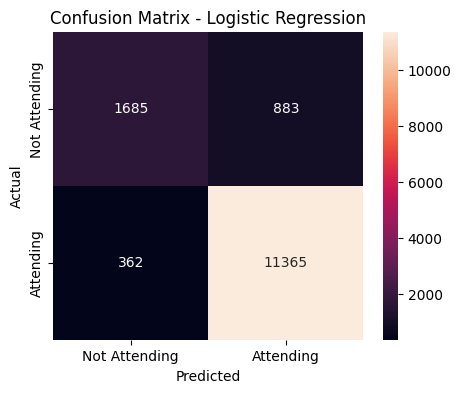

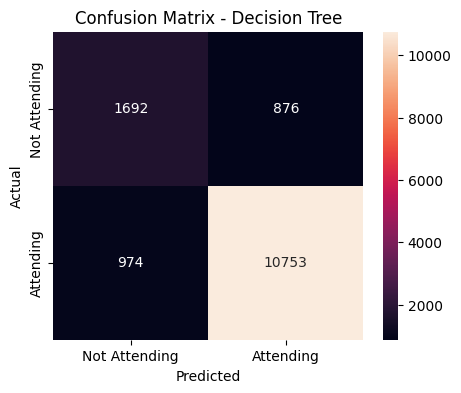

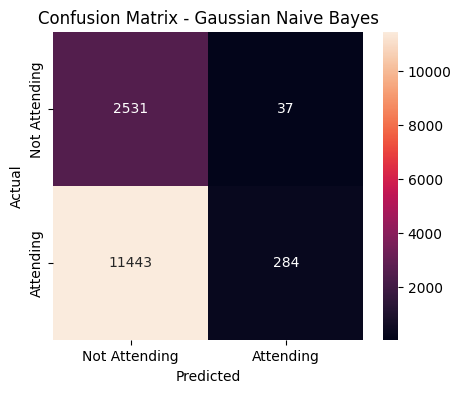

In [ ]:
# VISUALIZE CONFUSION MATRICES

for name in models:

    y_pred_test = predictions[name]["test"]

    cm = confusion_matrix(y_test, y_pred_test)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["Not Attending", "Attending"],
        yticklabels=["Not Attending", "Attending"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

### Interpretation of the Confusion Matrices

**What? → What happened? → So what? → What should we look at?**

**What?**  
The confusion matrices show the number of correct and incorrect predictions made for both attending and not-attending individuals.

**What happened?**  
For Logistic Regression, 1,685 individuals who were actually not attending were correctly identified as not attending, while 883 non-attending individuals were incorrectly classified as attending. The model also correctly identified 11,365 attending individuals.

For Decision Tree, 1,692 non-attending individuals were correctly identified, while 876 were incorrectly classified as attending.

Gaussian Naïve Bayes correctly identified 2,531 non-attending individuals and missed only 37, but it incorrectly classified 11,443 attending individuals as not attending.

**So what?**  
Gaussian Naïve Bayes has very high detection of the not-attending class, but this comes with a very large number of false positives. Logistic Regression has fewer false positives and provides a more balanced pattern of predictions.

**What should we look at?**  
We should specifically compare precision, recall, and F1-score for the not-attending class. This will show whether the models can identify non-attending individuals without producing too many incorrect alerts.

In [ ]:
# CLASSIFICATION REPORTS

for name in models:

    y_pred_test = predictions[name]["test"]

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred_test,
            target_names=["Not Attending", "Attending"]
        )
    )

Logistic Regression
               precision    recall  f1-score   support

Not Attending       0.82      0.66      0.73      2568
    Attending       0.93      0.97      0.95     11727

     accuracy                           0.91     14295
    macro avg       0.88      0.81      0.84     14295
 weighted avg       0.91      0.91      0.91     14295

Decision Tree
               precision    recall  f1-score   support

Not Attending       0.63      0.66      0.65      2568
    Attending       0.92      0.92      0.92     11727

     accuracy                           0.87     14295
    macro avg       0.78      0.79      0.78     14295
 weighted avg       0.87      0.87      0.87     14295

Gaussian Naive Bayes
               precision    recall  f1-score   support

Not Attending       0.18      0.99      0.31      2568
    Attending       0.88      0.02      0.05     11727

     accuracy                           0.20     14295
    macro avg       0.53      0.50      0.18     14295
 w

### Interpretation of the Classification Reports

The classification reports show that model performance differs between the two target classes. The models generally perform much better at identifying individuals who are attending school than those who are not attending.

This difference is important because the dataset is imbalanced, with attending individuals representing about 82% of the observations and not-attending individuals representing about 18%. Therefore, a model can achieve relatively high overall accuracy while still missing a considerable number of non-attending individuals.

For this reason, the performance of the not-attending class should be examined separately rather than relying only on overall accuracy.

In [ ]:
# PERFORMANCE FOR NOT-ATTENDING CLASS

not_attending_results = []

for name in models:

    y_pred_test = predictions[name]["test"]

    not_attending_results.append({
        "Model": name,
        "Precision_Not_Attending": precision_score(
            y_test,
            y_pred_test,
            pos_label=0
        ),
        "Recall_Not_Attending": recall_score(
            y_test,
            y_pred_test,
            pos_label=0
        ),
        "F1_Not_Attending": f1_score(
            y_test,
            y_pred_test,
            pos_label=0
        )
    })

not_attending_df = pd.DataFrame(not_attending_results)

not_attending_df

,Model,Precision_Not_Attending,Recall_Not_Attending,F1_Not_Attending
0,Logistic Regression,0.823156,0.656153,0.730228
1,Decision Tree,0.634659,0.658879,0.646542
2,Gaussian Naive Bayes,0.181122,0.985592,0.306009


### Interpretation of Not-Attending Performance

**Metric → Observation → Insight → Implication**

**Recall:** Logistic Regression identified approximately 65.62% of individuals who were actually not attending school. Decision Tree achieved approximately 65.89%, while Gaussian Naïve Bayes achieved approximately 98.56%.

**Precision:** Logistic Regression had approximately 82.32% precision for the not-attending class, compared with 63.47% for Decision Tree and only 18.12% for Gaussian Naïve Bayes.

**F1-score:** Logistic Regression achieved approximately 73.02%, Decision Tree approximately 64.65%, and Gaussian Naïve Bayes approximately 30.60% for the not-attending class.

**Insight:** Gaussian Naïve Bayes has the highest recall for the not-attending class, meaning it identifies almost all actual non-attending individuals. However, its very low precision shows that many of the individuals it identifies as not attending are actually attending. Logistic Regression has a lower recall but much higher precision and F1-score, indicating a more balanced performance.

**Implication:** The results show that identifying more actual non-attending individuals comes with a trade-off in false positives. Because of this trade-off, the final model assessment should consider additional measures such as PR-AUC, threshold analysis, and cross-validation rather than relying on a single metric.

## Part IV – Compare the Models

In [ ]:
# OVERALL TESTING COMPARISON

comparison_df = test_results_df.copy()

comparison_df[
    ["Accuracy", "Precision", "Recall", "F1"]
] = comparison_df[
    ["Accuracy", "Precision", "Recall", "F1"]
] * 100

comparison_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,91.290661,92.790660,96.913107,94.807091
1,Decision Tree,87.058412,92.467108,91.694380,92.079123
2,Gaussian Naive Bayes,19.692200,88.473520,2.421762,4.714475


In [ ]:
# NOT-ATTENDING CLASS COMPARISON

not_attending_comparison = not_attending_df.copy()

not_attending_comparison[
    [
        "Precision_Not_Attending",
        "Recall_Not_Attending",
        "F1_Not_Attending"
    ]
] = not_attending_comparison[
    [
        "Precision_Not_Attending",
        "Recall_Not_Attending",
        "F1_Not_Attending"
    ]
] * 100

not_attending_comparison

,Model,Precision_Not_Attending,Recall_Not_Attending,F1_Not_Attending
0,Logistic Regression,82.315584,65.615265,73.022752
1,Decision Tree,63.465866,65.887850,64.654184
2,Gaussian Naive Bayes,18.112208,98.559190,30.600895


In [ ]:
# COMBINED MODEL COMPARISON

combined_comparison = comparison_df[
    ["Model", "Accuracy", "Precision", "Recall", "F1"]
].merge(
    not_attending_comparison[
        [
            "Model",
            "Precision_Not_Attending",
            "Recall_Not_Attending",
            "F1_Not_Attending"
        ]
    ],
    on="Model"
)

combined_comparison

,Model,Accuracy,Precision,Recall,F1,Precision_Not_Attending,Recall_Not_Attending,F1_Not_Attending
0,Logistic Regression,91.290661,92.790660,96.913107,94.807091,82.315584,65.615265,73.022752
1,Decision Tree,87.058412,92.467108,91.694380,92.079123,63.465866,65.887850,64.654184
2,Gaussian Naive Bayes,19.692200,88.473520,2.421762,4.714475,18.112208,98.559190,30.600895


### Interpretation of Overall Model Comparison

**Metric → Observation → Insight → Implication**

**Accuracy:** Logistic Regression achieved the highest testing accuracy at approximately 91.29%, followed by Decision Tree at 87.06%. Gaussian Naïve Bayes had the lowest accuracy at approximately 19.69%.

**Observation:** Logistic Regression also achieved the highest F1-score for the attending class at approximately 94.81%.

**Insight:** Logistic Regression performed consistently well across the overall testing metrics. Decision Tree also performed reasonably well, while Gaussian Naïve Bayes showed substantially weaker overall classification performance.

**Implication:** Logistic Regression currently provides the strongest overall testing performance, but model selection should also consider the project's focus on identifying individuals who are not attending school.

In [ ]:
# CALCULATE AVERAGE PRECISION (PR-AUC) FOR BOTH CLASSES
# Class 1 = Attending; Class 0 = Not Attending
# Average Precision is calculated separately for each class using that class's predicted probability.

pr_auc_results = []

for name, model in models.items():
    probabilities = model.predict_proba(X_test)
    class_order = list(model.classes_)

    # Average Precision for class 1: Attending
    attending_index = class_order.index(1)
    attending_probabilities = probabilities[:, attending_index]
    ap_attending = average_precision_score(
        (y_test == 1).astype(int),
        attending_probabilities
    )

    # Average Precision for class 0: Not Attending
    not_attending_index = class_order.index(0)
    not_attending_probabilities = probabilities[:, not_attending_index]
    ap_not_attending = average_precision_score(
        (y_test == 0).astype(int),
        not_attending_probabilities
    )

    pr_auc_results.append({
        "Model": name,
        "AP_Attending": ap_attending,
        "AP_Not_Attending": ap_not_attending
    })

pr_auc_df = pd.DataFrame(pr_auc_results)

# Convert both Average Precision values to percentages for display
pr_auc_df[["AP_Attending", "AP_Not_Attending"]] *= 100

pr_auc_df.round(2)


,Model,AP_Attending,AP_Not_Attending
0,Logistic Regression,97.88,81.66
1,Decision Tree,91.60,47.94
2,Gaussian Naive Bayes,91.82,18.11


### Interpretation of Average Precision (PR-AUC)

**Metric → Observation → Insight → Implication**

**Metric:** Average Precision summarizes the precision-recall curve for a selected positive class. Because this project has two classes, calculate it separately for attending (class 1) and not attending (class 0). For the not-attending calculation, class 0 is temporarily treated as the positive class, and the model's predicted probability for class 0 is used.

**How to interpret the output:** Compare the models using both `AP_Attending` and `AP_Not_Attending`. The attending-class result describes how well the model ranks people who are attending school. The not-attending-class result is especially relevant to the project's support-identification goal. Do not assume the ranking will be the same for both classes.

**Implication:** Average Precision should be considered alongside not-attending precision, recall, F1-score, cross-validation stability, and the consequences of false positives and false negatives. A high value alone does not determine which threshold should be used or whether the model is ready for practical deployment.


In [ ]:
# FINAL PART IV COMPARISON TABLE

part4_comparison = combined_comparison.merge(
    pr_auc_df,
    on="Model"
)

part4_comparison

,Model,Accuracy,Precision,Recall,F1,Precision_Not_Attending,Recall_Not_Attending,F1_Not_Attending,AP_Attending,AP_Not_Attending
0,Logistic Regression,91.290661,92.790660,96.913107,94.807091,82.315584,65.615265,73.022752,97.876829,81.656008
1,Decision Tree,87.058412,92.467108,91.694380,92.079123,63.465866,65.887850,64.654184,91.600713,47.935285
2,Gaussian Naive Bayes,19.692200,88.473520,2.421762,4.714475,18.112208,98.559190,30.600895,91.819180,18.108792


### Part IV Summary

The comparison shows that the three models have different strengths. Logistic Regression achieved the highest overall testing accuracy and PR-AUC, while Decision Tree produced similar not-attending recall but lower overall performance. Gaussian Naïve Bayes achieved the highest recall for the not-attending class, but its low precision and overall accuracy indicate that it produces many false positives.

These results demonstrate that model performance depends on the metric being considered. Therefore, the final assessment should also examine training versus testing performance and cross-validation results to determine how well each model generalizes to unseen households.

## Part V – Analyze Generalization Performance

In [ ]:
# TRAINING VS TESTING ACCURACY

generalization_results = []

for name in models:

    train_accuracy = accuracy_score(
        y_train,
        predictions[name]["train"]
    )

    test_accuracy = accuracy_score(
        y_test,
        predictions[name]["test"]
    )

    generalization_results.append({
        "Model": name,
        "Training Accuracy": train_accuracy * 100,
        "Testing Accuracy": test_accuracy * 100,
        "Difference": (train_accuracy - test_accuracy) * 100
    })

generalization_df = pd.DataFrame(generalization_results)

generalization_df

,Model,Training Accuracy,Testing Accuracy,Difference
0,Logistic Regression,91.182922,91.290661,-0.107739
1,Decision Tree,99.981001,87.058412,12.922589
2,Gaussian Naive Bayes,19.770635,19.692200,0.078435


### Interpretation of Training vs Testing Performance

**Metric → Observation → Insight → Implication**

**Metric:** The difference between training and testing accuracy is used to examine how well each model generalizes to unseen data.

**Observation:** Logistic Regression had very similar training and testing accuracy, with a difference of approximately 0.11 percentage points. Gaussian Naïve Bayes also had a very small difference of approximately 0.08 percentage points, although both models had very different levels of overall performance. Decision Tree had almost perfect training accuracy at approximately 99.98% but only 87.06% testing accuracy, producing a much larger gap of approximately 12.92 percentage points.

**Insight:** The large gap between the Decision Tree's training and testing performance indicates that the tree may be overfitting the training data. Logistic Regression shows a much smaller train-test difference, indicating more consistent generalization.

**Implication:** Testing performance should be given more importance than training performance when assessing how the models may perform on unseen data. Cross-validation will provide additional evidence about the consistency of these results.

In [ ]:
# CREATE 5-FOLD GROUP-AWARE CROSS-VALIDATION

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold Stratified Group Cross-Validation created.")

5-fold Stratified Group Cross-Validation created.


In [ ]:
# RUN 5-FOLD CROSS-VALIDATION

cv_results = []

for name, model in models.items():

    fold_accuracies = []
    fold_precisions = []
    fold_recalls_attending = []
    fold_recalls_not_attending = []
    fold_f1_attending = []
    fold_ap_attending = []
    fold_ap_not_attending = []

    for train_idx_cv, val_idx_cv in cv.split(
        X,
        y,
        groups=groups
    ):

        # Clone the model so the original model remains unchanged
        fold_model = clone(model)

        # Split the data
        X_train_cv = X.iloc[train_idx_cv]
        X_val_cv = X.iloc[val_idx_cv]

        y_train_cv = y.iloc[train_idx_cv]
        y_val_cv = y.iloc[val_idx_cv]

        # Train model
        fold_model.fit(
            X_train_cv,
            y_train_cv
        )

        # Predictions and class probabilities
        y_pred_cv = fold_model.predict(X_val_cv)
        probabilities_cv = fold_model.predict_proba(X_val_cv)
        class_order_cv = list(fold_model.classes_)

        attending_index_cv = class_order_cv.index(1)
        not_attending_index_cv = class_order_cv.index(0)

        attending_probabilities_cv = probabilities_cv[:, attending_index_cv]
        not_attending_probabilities_cv = probabilities_cv[:, not_attending_index_cv]

        # Metrics
        fold_accuracies.append(
            accuracy_score(y_val_cv, y_pred_cv)
        )

        fold_precisions.append(
            precision_score(y_val_cv, y_pred_cv, zero_division=0)
        )

        fold_recalls_attending.append(
            recall_score(y_val_cv, y_pred_cv, pos_label=1, zero_division=0)
        )

        fold_recalls_not_attending.append(
            recall_score(y_val_cv, y_pred_cv, pos_label=0, zero_division=0)
        )

        fold_f1_attending.append(
            f1_score(y_val_cv, y_pred_cv, pos_label=1, zero_division=0)
        )

        # Average Precision for each class
        fold_ap_attending.append(
            average_precision_score(
                (y_val_cv == 1).astype(int),
                attending_probabilities_cv
            )
        )

        fold_ap_not_attending.append(
            average_precision_score(
                (y_val_cv == 0).astype(int),
                not_attending_probabilities_cv
            )
        )

    # Store mean and standard deviation across folds
    cv_results.append({
        "Model": name,
        "Accuracy_Mean": np.mean(fold_accuracies),
        "Accuracy_SD": np.std(fold_accuracies),
        "Precision_Mean": np.mean(fold_precisions),
        "Recall_Attending_Mean": np.mean(fold_recalls_attending),
        "Recall_Not_Attending_Mean": np.mean(fold_recalls_not_attending),
        "F1_Attending_Mean": np.mean(fold_f1_attending),
        "AP_Attending_Mean": np.mean(fold_ap_attending),
        "AP_Attending_SD": np.std(fold_ap_attending),
        "AP_Not_Attending_Mean": np.mean(fold_ap_not_attending),
        "AP_Not_Attending_SD": np.std(fold_ap_not_attending)
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df


,Model,Accuracy_Mean,Accuracy_SD,Precision_Mean,Recall_Attending_Mean,Recall_Not_Attending_Mean,F1_Attending_Mean,AP_Attending_Mean,AP_Attending_SD,AP_Not_Attending_Mean,AP_Not_Attending_SD
0,Logistic Regression,0.910818,0.002358,0.926239,0.968592,0.644730,0.946940,0.978785,0.000572,0.807686,0.007482
1,Decision Tree,0.872616,0.002264,0.923799,0.920928,0.650073,0.922355,0.915728,0.002854,0.479234,0.005634
2,Gaussian Naive Bayes,0.195429,0.002389,0.864243,0.024609,0.982210,0.047847,0.914968,0.002041,0.179584,0.003188


In [ ]:
# CONVERT CV RESULTS TO PERCENTAGES

cv_results_percent = cv_results_df.copy()

percentage_cols = [
    "Accuracy_Mean",
    "Accuracy_SD",
    "Precision_Mean",
    "Recall_Attending_Mean",
    "Recall_Not_Attending_Mean",
    "F1_Attending_Mean",
    "AP_Attending_Mean",
    "AP_Attending_SD",
    "AP_Not_Attending_Mean",
    "AP_Not_Attending_SD"
]

cv_results_percent[percentage_cols] = (
    cv_results_percent[percentage_cols] * 100
)

cv_results_percent.round(2)


,Model,Accuracy_Mean,Accuracy_SD,Precision_Mean,Recall_Attending_Mean,Recall_Not_Attending_Mean,F1_Attending_Mean,AP_Attending_Mean,AP_Attending_SD,AP_Not_Attending_Mean,AP_Not_Attending_SD
0,Logistic Regression,91.08,0.24,92.62,96.86,64.47,94.69,97.88,0.06,80.77,0.75
1,Decision Tree,87.26,0.23,92.38,92.09,65.01,92.24,91.57,0.29,47.92,0.56
2,Gaussian Naive Bayes,19.54,0.24,86.42,2.46,98.22,4.78,91.50,0.20,17.96,0.32


In [ ]:
# CV VS TEST COMPARISON

cv_test_comparison = cv_results_percent[
    [
        "Model",
        "Accuracy_Mean",
        "Accuracy_SD",
        "Recall_Not_Attending_Mean"
    ]
].merge(
    generalization_df[
        [
            "Model",
            "Testing Accuracy"
        ]
    ],
    on="Model"
)

cv_test_comparison

,Model,Accuracy_Mean,Accuracy_SD,Recall_Not_Attending_Mean,Testing Accuracy
0,Logistic Regression,91.081781,0.235822,64.472963,91.290661
1,Decision Tree,87.261593,0.226386,65.007270,87.058412
2,Gaussian Naive Bayes,19.542879,0.238936,98.220954,19.692200


### Interpretation of Cross-Validation Results

**Metric → Observation → Insight → Implication**

**Metric:** Five-fold Stratified Group Cross-Validation evaluates performance across multiple validation sets while keeping individuals from the same household within the same fold.

**Observation:** Review the mean and standard deviation for accuracy, not-attending recall, and Average Precision for both classes in the output above. `AP_Not_Attending_Mean` is the average not-attending Average Precision across the five folds, while `AP_Not_Attending_SD` shows how much it varied between folds.

**How to interpret the results:** A higher mean not-attending Average Precision indicates better ranking of people who are actually not attending school. A smaller standard deviation indicates more consistent results across folds. Consider these results alongside not-attending recall and the number of attending individuals who may be incorrectly flagged.

**Implication:** Use the actual values from the executed table when discussing cross-validation. Do not claim that a model is best for identifying non-attendance based on accuracy or attending-class Average Precision alone. The final choice should consider both classes, fold-to-fold stability, false-positive consequences, and stakeholder capacity.


### Part V Summary

The train-test comparison showed a substantial performance gap for Decision Tree, with nearly perfect training accuracy but lower testing accuracy, indicating possible overfitting. Logistic Regression had very similar training and testing performance, suggesting more consistent generalization. Gaussian Naïve Bayes had similar training and testing accuracy but poor overall classification performance.

Five-fold Stratified Group Cross-Validation produced results that were close to the final testing results for all three models. The small cross-validation standard deviations also indicate relatively stable accuracy across the folds. These results provide additional support for using the testing and cross-validation results together when assessing model performance.

### Part V: Generalization Questions

**1. Which model performed best on the training dataset?**

The **Decision Tree** performed best on the training dataset. It achieved an accuracy of approximately **99.98%**, which was much higher than Logistic Regression at **91.18%** and Gaussian Naïve Bayes at **19.77%**. This means the Decision Tree was able to fit the training data extremely closely.

**2. Which model performed best on the testing dataset?**

The **Logistic Regression** performed best on the testing dataset. It achieved approximately **91.29% accuracy**, compared with **87.06%** for Decision Tree and **19.69%** for Gaussian Naïve Bayes. Logistic Regression also had a strong F1-score of **94.81%** for the attending class and a not-attending recall of **65.62%**.

**3. Is there evidence of overfitting? Explain.**

Yes, there is evidence of **overfitting in the Decision Tree**. Its training accuracy was **99.98%**, but its testing accuracy dropped to **87.06%**, creating a gap of about **12.92 percentage points**. This suggests that the tree learned the training data very closely but did not perform as well on unseen individuals from different households.

Logistic Regression and Gaussian Naïve Bayes showed much smaller training-testing gaps, so there is less evidence of overfitting for these two models.

**4. Is there evidence of underfitting? Explain.**

There is evidence that **Gaussian Naïve Bayes is underfitting this dataset**. Its training accuracy was only **19.77%**, and its testing accuracy was similarly low at **19.69%**. Since the model performed poorly on both the training and testing data, it appears unable to capture the patterns needed for this classification problem.

Logistic Regression does not show strong evidence of underfitting because it achieved around **91% accuracy** on both training and testing data.

**5. Which model appears to generalize best?**

**Logistic Regression appears to generalize best.** Its training accuracy (**91.18%**) and testing accuracy (**91.29%**) were very close, with only about a **0.11 percentage-point difference**. Its five-fold cross-validation accuracy was also consistent at approximately **91.08%**, with a very small standard deviation of **0.24%**.

This suggests that Logistic Regression performs consistently not only on the training and testing datasets but also across different household-separated validation folds.


## Part VI: Additional Model Analysis

**Threshold Analysis**

We will start with **Logistic Regression** because it had the strongest overall testing and cross-validation performance.

The default classification threshold is **0.50.** We will test several thresholds to see how changing the threshold affects the model's ability to identify individuals who are **not attending school.**

In [ ]:
# Get predicted probabilities from Logistic Regression
# Column 0 = Not Attending
# Column 1 = Attending

logistic_model = models["Logistic Regression"]

prob_not_attending = logistic_model.predict_proba(X_test)[:, 0]

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (prob_not_attending >= threshold).astype(int)

    # Convert the prediction so:
    # 0 = Not Attending
    # 1 = Attending
    y_pred_threshold = np.where(prob_not_attending >= threshold, 0, 1)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred_threshold),
        "Precision_Not_Attending": precision_score(
            y_test, y_pred_threshold, pos_label=0
        ),
        "Recall_Not_Attending": recall_score(
            y_test, y_pred_threshold, pos_label=0
        ),
        "F1_Not_Attending": f1_score(
            y_test, y_pred_threshold, pos_label=0
        )
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results

,Threshold,Accuracy,Precision_Not_Attending,Recall_Not_Attending,F1_Not_Attending
0,0.2,0.876460,0.615495,0.832165,0.707616
1,0.3,0.902064,0.708125,0.773754,0.739486
2,0.4,0.913116,0.778571,0.721573,0.748989
3,0.5,0.912907,0.823156,0.656153,0.730228
4,0.6,0.907170,0.865645,0.572040,0.688863
5,0.7,0.899056,0.902073,0.491433,0.636249
6,0.8,0.885834,0.930939,0.393692,0.553366


In [ ]:
threshold_results_display = threshold_results.copy()

for col in [
    "Accuracy",
    "Precision_Not_Attending",
    "Recall_Not_Attending",
    "F1_Not_Attending"
]:
    threshold_results_display[col] *= 100

threshold_results_display.round(2)

,Threshold,Accuracy,Precision_Not_Attending,Recall_Not_Attending,F1_Not_Attending
0,0.2,87.65,61.55,83.22,70.76
1,0.3,90.21,70.81,77.38,73.95
2,0.4,91.31,77.86,72.16,74.90
3,0.5,91.29,82.32,65.62,73.02
4,0.6,90.72,86.56,57.20,68.89
5,0.7,89.91,90.21,49.14,63.62
6,0.8,88.58,93.09,39.37,55.34


### Interpretation of Threshold Analysis

**Metric → Observation → Insight → Implication**

**Metric:** The classification threshold determines how easily the Logistic Regression model classifies an individual as not attending school.

**Observation:** At the default threshold of 0.50, the model achieved 65.62% recall and 82.32% precision for the not-attending class. When the threshold was lowered to 0.40, not-attending recall increased to 72.16%, while the F1-score increased from 73.02% to 74.90%. The accuracy also slightly increased from 91.29% to 91.31%.

**Insight:** Lowering the threshold makes the model more willing to classify an individual as not attending school. This helps identify more actual non-attending individuals, but it also increases the possibility of false positives. On the other hand, increasing the threshold improves precision but reduces recall for the not-attending class.

**Implication:** The threshold should depend on the purpose of the prediction. If the priority is to identify more individuals who may be at risk of non-attendance, a lower threshold could be considered. However, the threshold should be validated using additional criteria before being used in an actual decision-support setting.

### Subgroup Recall Analysis

The recall for the not-attending class is calculated separately for different demographic and geographic groups. These results are used as investigation signals to determine whether model performance differs substantially across groups.

In [ ]:
# Generate final Logistic Regression predictions using the default 0.50 threshold

logistic_predictions = models["Logistic Regression"].predict(X_test)

# Create subgroup analysis dataset
subgroup_test = X_test.copy()

# Add actual and predicted values
subgroup_test["Actual"] = y_test.values
subgroup_test["Predicted"] = logistic_predictions

# Add Age Group from the original cleaned dataset
subgroup_test["Age Group"] = df_ml.loc[X_test.index, "Age Group"].values

In [ ]:
# Sex

sex_recall = (
    subgroup_test.groupby("Sex")
    .apply(
        lambda group: recall_score(
            group["Actual"],
            group["Predicted"],
            pos_label=0,
            zero_division=0
        )
    )
    .reset_index(name="Recall_Not_Attending")
)

sex_recall["Recall_Not_Attending"] *= 100

sex_recall.round(2)

/tmp/ipykernel_581/2217832560.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,Sex,Recall_Not_Attending
0,Female,65.30
1,Male,65.85


### Interpretation: Sex

**Metric → Observation → Insight → Implication**

**Metric:** Recall for the not-attending class was compared between male and female individuals.

**Observation:** The model achieved approximately 65.85% recall for males and 65.30% for females, giving a difference of only about 0.55 percentage points.

**Insight:** The model's ability to identify non-attending individuals was relatively similar between the two sex groups in the test set.

**Implication:** Sex does not show a large recall difference in this analysis. However, this result alone does not establish that the model is fully fair because other metrics and subgroups should also be examined.

In [ ]:
# Age Group

age_recall = (
    subgroup_test.groupby("Age Group")
    .apply(
        lambda group: recall_score(
            group["Actual"],
            group["Predicted"],
            pos_label=0,
            zero_division=0
        )
    )
    .reset_index(name="Recall_Not_Attending")
)

age_recall["Recall_Not_Attending"] *= 100

age_recall.round(2)

/tmp/ipykernel_581/2583414835.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,Age Group,Recall_Not_Attending
0,10–12,17.86
1,13–15,20.51
2,16–18,39.38
3,19–24,77.71
4,5–9,3.35


### Interpretation: Age Group

**Metric → Observation → Insight → Implication**

**Metric:** Recall for the not-attending class was compared across five age groups.

**Observation:** Recall varied substantially across age groups. The model achieved approximately 77.71% recall for ages 19–24, but only 3.35% for ages 5–9. The other groups ranged from approximately 17.86% to 39.38%.

**Insight:** The model's ability to identify non-attending individuals differs considerably by age group. It performs much better at identifying non-attendance among older individuals than among younger children.

**Implication:** Age-group differences should be investigated further before using the model for decision support. The differences may be related to the underlying data patterns, class distribution, available predictors, or how school attendance is represented across age groups. These differences should not automatically be interpreted as proof of unfairness.

In [ ]:
# Region

region_recall = (
    subgroup_test.groupby("Region")
    .apply(
        lambda group: recall_score(
            group["Actual"],
            group["Predicted"],
            pos_label=0,
            zero_division=0
        )
    )
    .reset_index(name="Recall_Not_Attending")
)

region_recall["Recall_Not_Attending"] *= 100

region_recall = region_recall.sort_values(
    "Recall_Not_Attending",
    ascending=False
)

region_recall.round(2)

/tmp/ipykernel_581/1570975959.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,Region,Recall_Not_Attending
11,Region VII - Central Visayas,75.16
4,Region I - Ilocos Region,73.91
6,Region III - Central Luzon,73.12
13,Region X - Northern Mindanao,72.32
3,National Capital Region,71.20
14,Region XI - Davao,67.88
7,Region IVA - CALABARZON,67.39
0,BARMM,64.21
16,Region XIII - Caraga,64.15
5,Region II - Cagayan Valley,63.86


### Interpretation: Region

**Metric → Observation → Insight → Implication**

**Metric:** Recall for the not-attending class was compared across the different Philippine regions.

**Observation:** Recall varied across regions. The highest observed recall was approximately 75.16% in Region VII - Central Visayas, while the lowest was approximately 50.91% in Region IX - Zamboanga Peninsula, resulting in a difference of about 24.25 percentage points.

**Insight:** The model does not identify non-attending individuals equally well across all regions. This indicates that geographic differences in prediction performance exist within the test data.

**Implication:** Regional performance should be monitored carefully. A large recall difference can be a signal to investigate differences in the data, sample sizes, feature patterns, or model behavior across regions. It should not automatically be treated as proof that the model is unfair.

In [ ]:
# Urbal/Rural

urban_rural_recall = (
    subgroup_test.groupby("Urban / Rural")
    .apply(
        lambda group: recall_score(
            group["Actual"],
            group["Predicted"],
            pos_label=0,
            zero_division=0
        )
    )
    .reset_index(name="Recall_Not_Attending")
)

urban_rural_recall["Recall_Not_Attending"] *= 100

urban_rural_recall.round(2)

/tmp/ipykernel_581/1992080018.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,Urban / Rural,Recall_Not_Attending
0,Rural,64.63
1,Urban,66.72


### Interpretation: Urban/Rural

**Metric → Observation → Insight → Implication**

**Metric:** Recall for the not-attending class was compared between urban and rural individuals.

**Observation:** The model achieved approximately 66.72% recall in urban areas and 64.63% in rural areas, giving a difference of about 2.09 percentage points.

**Insight:** The difference between urban and rural groups is relatively small compared with the larger differences observed across age groups and regions.

**Implication:** Urban/rural status does not show a large recall gap in this test set. However, it should still be monitored alongside other fairness measures if the model is used for decision support.

## Part VII: Final Model Evaluation and Discussion

### **Final Model Performance Comparison**

The final comparison focuses on the testing results because testing data represents unseen observations. Cross-validation results are also considered to assess whether the models maintain consistent performance across different household groups.

In [ ]:
# Create a final comparison table using the testing results

final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Gaussian Naive Bayes"
    ],
    "Test Accuracy (%)": [
        91.2907,
        87.0584,
        19.6922
    ],
    "Test Precision (%)": [
        92.7907,
        92.4671,
        88.4735
    ],
    "Test Recall Attending (%)": [
        96.9131,
        91.6944,
        2.4218
    ],
    "Test Recall Not Attending (%)": [
        65.6200,
        65.8900,
        98.5600
    ],
    "Test F1 Attending (%)": [
        94.8071,
        92.0791,
        4.7145
    ],
    "PR-AUC (%)": [
        97.8768,
        91.6007,
        91.8192
    ]
})

final_comparison.round(2)

,Model,Test Accuracy (%),Test Precision (%),Test Recall Attending (%),Test Recall Not Attending (%),Test F1 Attending (%),PR-AUC (%)
0,Logistic Regression,91.29,92.79,96.91,65.62,94.81,97.88
1,Decision Tree,87.06,92.47,91.69,65.89,92.08,91.60
2,Gaussian Naive Bayes,19.69,88.47,2.42,98.56,4.71,91.82


### Interpretation of Final Model Performance

**Metric → Observation → Insight → Implication**

**Metric:** Testing accuracy, precision, recall, F1-score, PR-AUC, and not-attending recall were compared across the three models.

**Observation:** Logistic Regression achieved the highest testing accuracy at 91.29%, followed by Decision Tree at 87.06%. Gaussian Naïve Bayes had a much lower accuracy of 19.69%. Logistic Regression also achieved the highest PR-AUC at 97.88%.

For the not-attending class, Gaussian Naïve Bayes achieved the highest recall at approximately 98.56%, while Logistic Regression achieved 65.62% and Decision Tree achieved 65.89%.

**Insight:** The models have different strengths. Logistic Regression provides the strongest overall performance and the best balance across the evaluated metrics. Decision Tree performs reasonably well but has a larger training-testing gap. Gaussian Naïve Bayes is highly sensitive to the not-attending class but produces many false positives, resulting in poor overall performance.

**Implication:** Model selection should consider the purpose of the prediction rather than relying on a single metric. For this project, overall consistency, generalization, and the ability to identify the not-attending class are important because the model is intended as decision support for education-related analysis.

### Model Generalization Summary

**Generalization Comparison**

| Model | Training Accuracy | Testing Accuracy | CV Accuracy | Accuracy Gap |
|---|---:|---:|---:|---:|
| Logistic Regression | 91.18% | 91.29% | 91.08% | 0.11 pp |
| Decision Tree | 99.98% | 87.06% | 87.26% | 12.92 pp |
| Gaussian Naive Bayes | 19.77% | 19.69% | 19.54% | 0.08 pp |

### Interpretation of Generalization

**Metric → Observation → Insight → Implication**

**Metric:** Training accuracy, testing accuracy, and five-fold Stratified Group Cross-Validation accuracy were compared to evaluate generalization.

**Observation:** Logistic Regression had very similar training, testing, and cross-validation accuracy, at approximately 91.18%, 91.29%, and 91.08%, respectively. Decision Tree had a very high training accuracy of 99.98%, but its testing and cross-validation accuracy were lower at approximately 87.06% and 87.26%. Gaussian Naïve Bayes had low accuracy across all three evaluations.

**Insight:** The large gap between training and testing performance for Decision Tree suggests overfitting. Logistic Regression showed much more consistent performance across the different evaluation methods. Gaussian Naïve Bayes did not show a large train-test gap, but its consistently low performance indicates that it was not capturing the patterns in the data effectively.

**Implication:** The results indicate that Logistic Regression generalizes most consistently among the three models. Its similar performance across training, testing, and household-separated cross-validation suggests that its results are less dependent on a particular training sample.

### Model Strengths and Weaknesses

**Logistic Regression**

* Strongest overall testing accuracy.
* Highest PR-AUC.
* Small training-testing difference.
* Stable cross-validation performance.
* More balanced performance between the two classes compared with Gaussian Naïve Bayes.

**Decision Tree**

* Extremely high training performance.
* Reasonable testing performance.
* Similar cross-validation and testing accuracy.
* Large training-testing gap indicates possible overfitting.

**Gaussian Naïve Bayes**

* Very high recall for the not-attending class.
* Very low overall accuracy.
* Very low recall for the attending class.
* Large number of false positives.
* Consistently poor overall performance across training, testing, and cross-validation.

### Subgroup Analysis Summary

**Fairness and Subgroup Findings**

The subgroup analysis of Logistic Regression showed different recall levels for identifying individuals who were not attending school.

| Subgroup    |     Highest Recall |     Lowest Recall | Approximate Gap |
| ----------- | -----------------: | ----------------: | --------------: |
| Sex         |       Male: 65.85% |    Female: 65.30% |         0.55 pp |
| Age Group   |      19–24: 77.71% |        5–9: 3.35% |        74.35 pp |
| Region      | Region VII: 75.16% | Region IX: 50.91% |        24.25 pp |
| Urban/Rural |      Urban: 66.72% |     Rural: 64.63% |         2.09 pp |


### Interpretation of Subgroup Findings

**Metric → Observation → Insight → Implication**

**Metric:** Recall for the not-attending class was examined across sex, age group, region, and urban/rural status.

**Observation:** The smallest differences were observed between sex groups and urban/rural groups. Much larger differences appeared across age groups and regions.

**Insight:** The model's ability to identify non-attending individuals is not equally consistent across all subgroups. The particularly large age-group difference indicates that younger and older groups should be examined separately when evaluating model performance.

**Implication:** These differences should be treated as signals for further investigation rather than automatic evidence of unfairness. Before any real-world use, subgroup performance should be monitored and additional fairness measures should be considered. The model should also remain a decision-support tool rather than an automatic system for determining who receives educational assistance.

## Overall Discussion

The evaluation shows that the three models behave differently on the school-attendance classification task. Decision Tree achieved the highest training accuracy, but its large training-testing gap indicates possible overfitting. Gaussian Naïve Bayes showed the highest recall for the not-attending class, but its very low overall accuracy and large number of false positives limited its overall usefulness.

Logistic Regression produced the strongest and most consistent overall results. It achieved approximately 91.29% testing accuracy, 97.88% PR-AUC, and 91.08% mean cross-validation accuracy. Its training and testing results were also very close, suggesting good generalization across unseen household groups.

However, Logistic Regression did not identify all non-attending individuals. Its not-attending recall was approximately 65.62% at the default threshold, although threshold analysis showed that lowering the threshold to 0.40 increased not-attending recall to approximately 72.16% and the not-attending F1-score to 74.90%.

Subgroup analysis also showed substantial differences in not-attending recall across age groups and regions. These results highlight the importance of checking model performance across different populations rather than relying only on overall accuracy.

Overall, the results support using Logistic Regression as the main model for further analysis in this project, while recognizing its limitations and the need for additional validation, threshold evaluation, and subgroup monitoring.